# 全通道两轮全局 beta 聚类

手动选择病人与 block；每个病人 × block × 通道是一条样本。第一轮分类及 PCA → 一次自动筛除小而高方差的簇 → 弹窗人工剔除 → 第二轮重新拟合。两轮类数手动选择，两轮都展示 beta 与音频的关系。

In [1]:
from pathlib import Path
import os
import sys
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MPLBACKEND", "Agg")

# 支持从项目根目录或 all-channel 目录启动。
cwd = Path.cwd().resolve()
PROJECT_DIR = cwd if (cwd / "inputs.py").is_file() else cwd / "all-channel"
if not (PROJECT_DIR / "inputs.py").is_file():
    raise RuntimeError("请从项目根目录或 all-channel 目录启动 Notebook。")
for directory in (PROJECT_DIR.parent, PROJECT_DIR):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))
import pandas as pd
import importlib
import json
# 更新后重新运行本单元，避免同一内核继续使用旧模块。
for name in ("inputs", "dynamics", "full_curves", "native_curves", "curve_similarity", "plots", "pipeline", "auto_prune", "review"):
    if name in sys.modules:
        importlib.reload(sys.modules[name])
from IPython.display import display, Image
from inputs import list_available_blocks, build_manifest, inspect_manifest, validate_manifest
from pipeline import run_analysis, refresh_saved_plots
from review import pca_review_table, run_second_round
from auto_prune import screen_small_high_variance_clusters, show_pruned_review_window
print("项目目录：", PROJECT_DIR)
print("Python：", sys.executable)

项目目录： I:\贝塔频带汇报-2026-10\all-channel
Python： e:\anaconda\envs\ECoG_LR_v1\python.exe


## 1. 参数区

`INCLUDED_BLOCKS` 的每个键是病人编号，值是要纳入的 block 列表。`FIRST_N_CLUSTERS` 和 `SECOND_N_CLUSTERS` 分别手动指定两轮类数，不自动选择 K。默认使用病人基线文件；不自动切换基线来源。

In [35]:
DATA_ROOT = Path(r"I:\ECoG_data")

INCLUDED_BLOCKS = {
     "HS0012": ["B01", "B03", "B02", "B05"],
     "HS0006": ["B07", "B08", "B09"],
     "HS0013": ["B01", "B03", "B02", "B05"],
     #"HS0015": ["B03", "B04", "B05", "B06"],
}

FIRST_N_CLUSTERS = 8
BASELINE_MODE = "file"  # "file" 或 "pre_onset"；所有 block 使用同一模式
RANDOM_STATE = 50
CORRELATION_THRESHOLD = 0.95
PROGRESS_POINTS = 101
DURATION_MAD_THRESHOLD = 2.5
MIN_TRIALS_AFTER_FILTER = 3
PRE_POST_WINDOW_SECONDS = None  # None 使用 CURVE_CONTEXT_SECONDS；明确填更短值时使用更短窗口
BASELINE_WINDOW_SECONDS = (-1.3, -0.3)
BASELINE_RELATIVE_FLOOR = 1e-3
BASELINE_EDGE_SECONDS = 0.3
FEATURE_SMOOTH_SIGMA_SECONDS = 0.06
FEATURE_SLOPE_METHOD = "savgol"
MAX_BASELINE_INVALID_FRACTION = 0.25
OUTPUT_ROOT = PROJECT_DIR / "outputs"
SECOND_N_CLUSTERS = 2  # 手动选择第二轮类数
DISPLAY_SMOOTH_SIGMA_SECONDS = 0.10
CURVE_CONTEXT_SECONDS = 0.75
CURVE_CONTEXT_POINTS = 51
SAVE_CHANNEL_FIGURES = True

## 2. 查看可用病人和 block

只扫描目录和文件是否存在，不纳入任何数据，也不读取信号。`ready` 表示当前基线模式所需文件齐全；记录内容是否合法由正式提取流程检查。

In [36]:
available_blocks = list_available_blocks(DATA_ROOT)
if BASELINE_MODE == "pre_onset" and not available_blocks.empty:
    available_blocks["baseline_mode"] = BASELINE_MODE
    available_blocks = inspect_manifest(available_blocks.drop(columns=["ready", "missing_files"]))
display(available_blocks[["subject_id", "block_id", "ready", "missing_files"]])
print(f"发现 {available_blocks.subject_id.nunique()} 个病人、{len(available_blocks)} 个 standardized block。")

,subject_id,block_id,ready,missing_files
0,HS0005,B01,True,
1,HS0005,B02,True,
2,HS0005,B03,True,
3,HS0005,B04,True,
4,HS0005,B05,True,
...,...,...,...,...
110,HS0058,B05,False,fif_path: I:\ECoG_data\HS0058\blocks\B05\stand...
111,HS0066,B01,False,fif_path: I:\ECoG_data\HS0066\blocks\B01\stand...
112,HS0066,B02,False,fif_path: I:\ECoG_data\HS0066\blocks\B02\stand...
113,HS0066,B03,False,fif_path: I:\ECoG_data\HS0066\blocks\B03\stand...


发现 16 个病人、115 个 standardized block。


## 3. 检查手动选择

填写参数区后重新运行参数区及本单元。缺失任一必要文件即停止，错误信息包含全部缺失路径。

In [37]:
if not INCLUDED_BLOCKS:
    print("尚未选择数据。请填写参数区的 INCLUDED_BLOCKS。")
    manifest = None
else:
    manifest = build_manifest(DATA_ROOT, INCLUDED_BLOCKS, baseline_mode=BASELINE_MODE)
    display(inspect_manifest(manifest))
    validate_manifest(manifest)
    print(f"检查通过：{manifest.subject_id.nunique()} 个病人，{len(manifest)} 个 block。")

,subject_id,block_id,baseline_mode,fif_path,onset_path,offset_path,wav_path,baseline_fif,ready,missing_files
0,HS0012,B01,file,I:\ECoG_data\HS0012\blocks\B01\standardized\EC...,I:\ECoG_data\HS0012\blocks\B01\standardized\ev...,I:\ECoG_data\HS0012\blocks\B01\standardized\ev...,I:\ECoG_data\HS0012\blocks\B01\standardized\au...,I:\ECoG_data\HS0012\baseline\baseline.fif,True,
1,HS0012,B03,file,I:\ECoG_data\HS0012\blocks\B03\standardized\EC...,I:\ECoG_data\HS0012\blocks\B03\standardized\ev...,I:\ECoG_data\HS0012\blocks\B03\standardized\ev...,I:\ECoG_data\HS0012\blocks\B03\standardized\au...,I:\ECoG_data\HS0012\baseline\baseline.fif,True,
2,HS0012,B02,file,I:\ECoG_data\HS0012\blocks\B02\standardized\EC...,I:\ECoG_data\HS0012\blocks\B02\standardized\ev...,I:\ECoG_data\HS0012\blocks\B02\standardized\ev...,I:\ECoG_data\HS0012\blocks\B02\standardized\au...,I:\ECoG_data\HS0012\baseline\baseline.fif,True,
3,HS0012,B05,file,I:\ECoG_data\HS0012\blocks\B05\standardized\EC...,I:\ECoG_data\HS0012\blocks\B05\standardized\ev...,I:\ECoG_data\HS0012\blocks\B05\standardized\ev...,I:\ECoG_data\HS0012\blocks\B05\standardized\au...,I:\ECoG_data\HS0012\baseline\baseline.fif,True,
4,HS0006,B07,file,I:\ECoG_data\HS0006\blocks\B07\standardized\EC...,I:\ECoG_data\HS0006\blocks\B07\standardized\ev...,I:\ECoG_data\HS0006\blocks\B07\standardized\ev...,I:\ECoG_data\HS0006\blocks\B07\standardized\au...,I:\ECoG_data\HS0006\baseline\baseline.fif,True,
5,HS0006,B08,file,I:\ECoG_data\HS0006\blocks\B08\standardized\EC...,I:\ECoG_data\HS0006\blocks\B08\standardized\ev...,I:\ECoG_data\HS0006\blocks\B08\standardized\ev...,I:\ECoG_data\HS0006\blocks\B08\standardized\au...,I:\ECoG_data\HS0006\baseline\baseline.fif,True,
6,HS0006,B09,file,I:\ECoG_data\HS0006\blocks\B09\standardized\EC...,I:\ECoG_data\HS0006\blocks\B09\standardized\ev...,I:\ECoG_data\HS0006\blocks\B09\standardized\ev...,I:\ECoG_data\HS0006\blocks\B09\standardized\au...,I:\ECoG_data\HS0006\baseline\baseline.fif,True,
7,HS0013,B01,file,I:\ECoG_data\HS0013\blocks\B01\standardized\EC...,I:\ECoG_data\HS0013\blocks\B01\standardized\ev...,I:\ECoG_data\HS0013\blocks\B01\standardized\ev...,I:\ECoG_data\HS0013\blocks\B01\standardized\au...,I:\ECoG_data\HS0013\baseline\baseline.fif,True,
8,HS0013,B03,file,I:\ECoG_data\HS0013\blocks\B03\standardized\EC...,I:\ECoG_data\HS0013\blocks\B03\standardized\ev...,I:\ECoG_data\HS0013\blocks\B03\standardized\ev...,I:\ECoG_data\HS0013\blocks\B03\standardized\au...,I:\ECoG_data\HS0013\baseline\baseline.fif,True,
9,HS0013,B02,file,I:\ECoG_data\HS0013\blocks\B02\standardized\EC...,I:\ECoG_data\HS0013\blocks\B02\standardized\ev...,I:\ECoG_data\HS0013\blocks\B02\standardized\ev...,I:\ECoG_data\HS0013\blocks\B02\standardized\au...,I:\ECoG_data\HS0013\baseline\baseline.fif,True,


检查通过：3 个病人，11 个 block。


## 4. 执行第一轮分类

从连续原生 beta Hilbert 功率和音频直接生成整段曲线：连续信号先统一平滑，再在每个 trial 上一次取样；不把分别平滑的 pre/speech/post 曲线拼起来。每个通道再汇总配对有效 trial。分类使用包含语音前后上下文的完整连续 beta 曲线，减去各通道语音前平均功率，再除以该通道整条 pre/speech/post 曲线的 RMS，去除幅度差异；保留方向与各段相对形状。整条平坦曲线保持为零。再加入 beta/audio 斜率零延迟相关、峰值互相关及相应延迟。逐通道归一化后再使用共享训练尺度配权；按 pre/speech/post=0.2/0.6/0.2 和音频关系=0.25 分配权重，以加权欧氏距离做 K-means。旧功率/能量指标仅保存作诊断，不进入分类，也不对 PNG 像素聚类。PCA 是加权特征的可视化。每次运行使用独立目录；复审和第二轮不会重新读取 FIF。

In [38]:
from datetime import datetime
if not INCLUDED_BLOCKS:
    raise ValueError("请先填写 INCLUDED_BLOCKS，再运行检查与分析单元。")
# 重新解析当前选择，避免沿用旧检查单元中的 manifest。
manifest = build_manifest(DATA_ROOT, INCLUDED_BLOCKS, baseline_mode=BASELINE_MODE)
validate_manifest(manifest)
RUN_DIR = OUTPUT_ROOT / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
first_analysis = run_analysis(
    manifest, RUN_DIR, n_clusters=FIRST_N_CLUSTERS, random_state=RANDOM_STATE,
    correlation_threshold=CORRELATION_THRESHOLD, progress_points=PROGRESS_POINTS,
    duration_mad_threshold=DURATION_MAD_THRESHOLD,
    min_trials_after_filter=MIN_TRIALS_AFTER_FILTER, pre_post_window=PRE_POST_WINDOW_SECONDS,
    baseline_window=BASELINE_WINDOW_SECONDS, baseline_relative_floor=BASELINE_RELATIVE_FLOOR,
    baseline_edge_seconds=BASELINE_EDGE_SECONDS,
    smoothing_sigma_seconds=FEATURE_SMOOTH_SIGMA_SECONDS, slope_method=FEATURE_SLOPE_METHOD,
    max_baseline_invalid_fraction=MAX_BASELINE_INVALID_FRACTION,
    display_sigma_seconds=DISPLAY_SMOOTH_SIGMA_SECONDS,
    curve_context_seconds=CURVE_CONTEXT_SECONDS, curve_context_points=CURVE_CONTEXT_POINTS,
    save_channel_figures=SAVE_CHANNEL_FIGURES,
)
review_ready = False  # 新的第一轮必须重新自动筛除与人工复审。
print("第一轮输出目录：", first_analysis.output_dir)
display(pd.read_csv(RUN_DIR / "block_summary.csv"))
display(first_analysis.assignments.head(20))

[1/11] HS0012/B01
Reading 0 ... 52800  =      0.000 ...   132.000 secs...
Reading 0 ... 52800  =      0.000 ...   132.000 secs...
[2/11] HS0012/B03
Reading 0 ... 107200  =      0.000 ...   268.000 secs...
Reading 0 ... 107200  =      0.000 ...   268.000 secs...
[3/11] HS0012/B02
Reading 0 ... 203200  =      0.000 ...   508.000 secs...
Reading 0 ... 203200  =      0.000 ...   508.000 secs...
[4/11] HS0012/B05
Reading 0 ... 132000  =      0.000 ...   330.000 secs...
Reading 0 ... 132000  =      0.000 ...   330.000 secs...
[5/11] HS0006/B07
Reading 0 ... 109200  =      0.000 ...   273.000 secs...
Reading 0 ... 109200  =      0.000 ...   273.000 secs...
[6/11] HS0006/B08
Reading 0 ... 96000  =      0.000 ...   240.000 secs...
Reading 0 ... 96000  =      0.000 ...   240.000 secs...
[7/11] HS0006/B09
Reading 0 ... 82400  =      0.000 ...   206.000 secs...
Reading 0 ... 82400  =      0.000 ...   206.000 secs...
[8/11] HS0013/B01
Reading 0 ... 83200  =      0.000 ...   208.000 secs...
Reading 

,subject_id,block_id,n_channels,n_included_channels,n_valid_trials,n_dropped_trials
0,HS0012,B01,128,126,12,1
1,HS0012,B03,128,126,50,4
2,HS0012,B02,128,126,40,8
3,HS0012,B05,128,127,49,3
4,HS0006,B07,256,243,42,7
5,HS0006,B08,256,243,43,6
6,HS0006,B09,256,243,44,5
7,HS0013,B01,128,127,48,3
8,HS0013,B03,128,127,44,6
9,HS0013,B02,128,125,45,6


,subject_id,block_id,sample_id,channel,is_bad,baseline_invalid_fraction,valid_trial_count,n_block_trials,exclusion_reason,curve_valid_trial_count,label,pc1,pc2,pc3
0,HS0012,B01,HS0012:B01:ECoG_1,ECoG_1,False,0.0,12,12,,12,7,0.637641,-0.136146,0.166847
1,HS0012,B01,HS0012:B01:ECoG_2,ECoG_2,False,0.0,12,12,,12,5,0.695043,-0.184134,0.080039
2,HS0012,B01,HS0012:B01:ECoG_3,ECoG_3,False,0.0,12,12,,12,7,0.449212,-0.052692,0.083605
3,HS0012,B01,HS0012:B01:ECoG_4,ECoG_4,False,0.0,12,12,,12,1,0.309656,0.174442,0.322951
4,HS0012,B01,HS0012:B01:ECoG_5,ECoG_5,False,0.0,12,12,,12,7,0.375924,0.204249,0.234045
5,HS0012,B01,HS0012:B01:ECoG_6,ECoG_6,False,0.0,12,12,,12,7,0.576826,0.148596,0.033216
6,HS0012,B01,HS0012:B01:ECoG_7,ECoG_7,False,0.0,12,12,,12,7,0.520378,0.150304,0.017856
7,HS0012,B01,HS0012:B01:ECoG_8,ECoG_8,False,0.0,12,12,,12,7,0.359967,0.238001,-0.013218
8,HS0012,B01,HS0012:B01:ECoG_9,ECoG_9,False,0.0,12,12,,12,6,0.143663,0.274481,-0.098210
9,HS0012,B01,HS0012:B01:ECoG_10,ECoG_10,False,0.0,12,12,,12,6,-0.027943,0.254320,0.001405


## 5. 查看第一轮 PCA、异常距离与音频关系

先展示完整 pre/speech/post beta 与橙色音频的双轴主图，随后是 PCA、语音段曲线及斜率诊断。图和分类均使用去水平、去幅度后的无量纲 beta 变化，不展示 beta Z。毫秒轴的语音长度取全部 trial 时长中位数，pre/post 为固定真实秒数。每个通道图与 trial SEM 的路径见 channel_figure_index.csv。按到所属簇中心的前三 PC 欧氏距离排序可定位偏离样本；它不是显著性阈值。样本用 `病人:block:通道` 唯一标识。音频按各 block speech 峰值归一化。

{'n_samples': 1792,
 'n_included': 1740,
 'n_requested_clusters': 8,
 'n_actual_clusters': 8,
 'min_cluster_size': 41,
 'silhouette': 0.20099100675865236,
 'silhouette_sample_cap': 5000,
 'stability_evaluated': False,
 'interpretation': 'Descriptive clustering and paired beta/audio curves; sample SEM is not a stability test.',
 'classification_mode': 'curve_shape',
 'distance': 'weighted Euclidean',
 'beta_centering': 'subtract each sample pre-onset mean; divide full curve by its own RMS',
 'shared_beta_scale': 1.0}

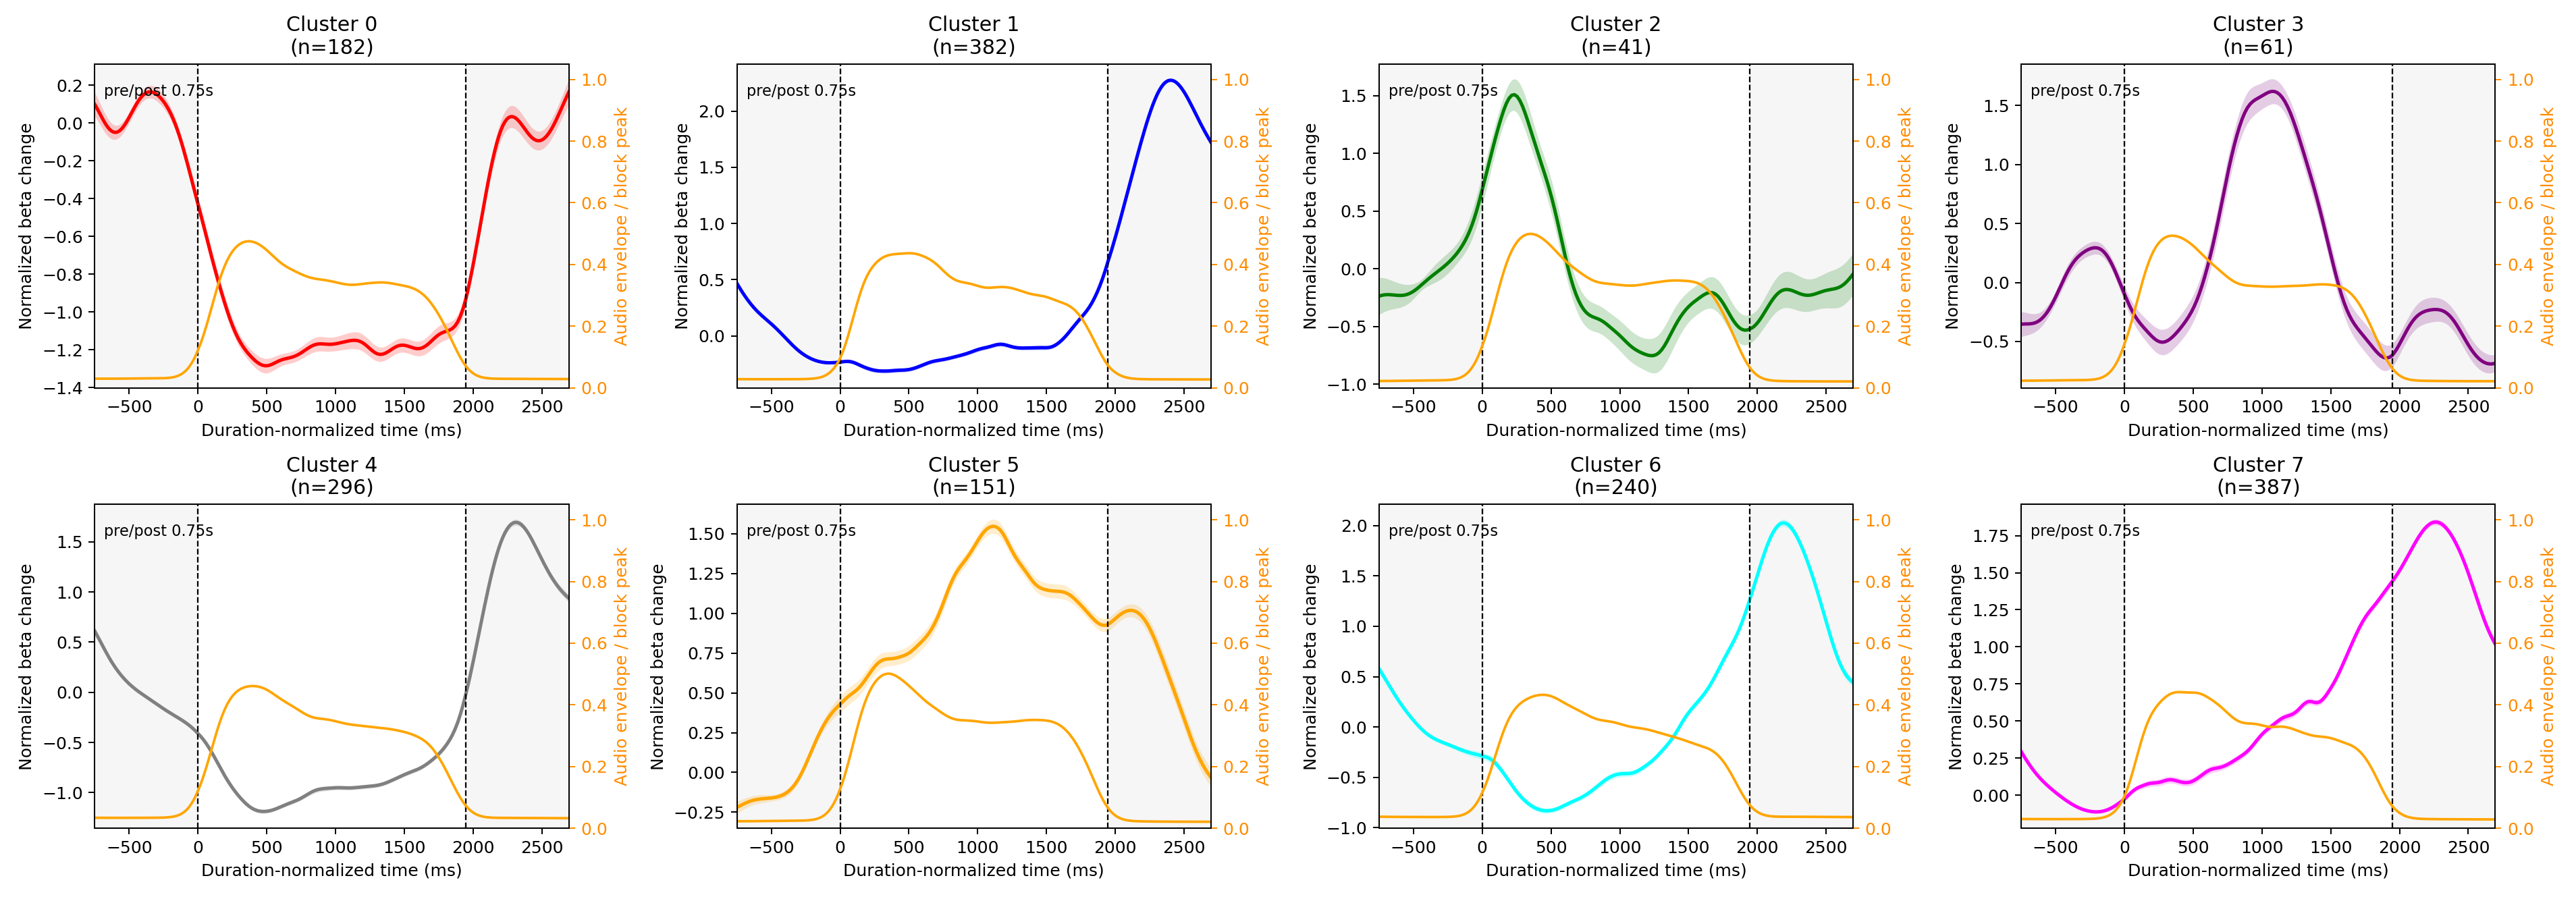

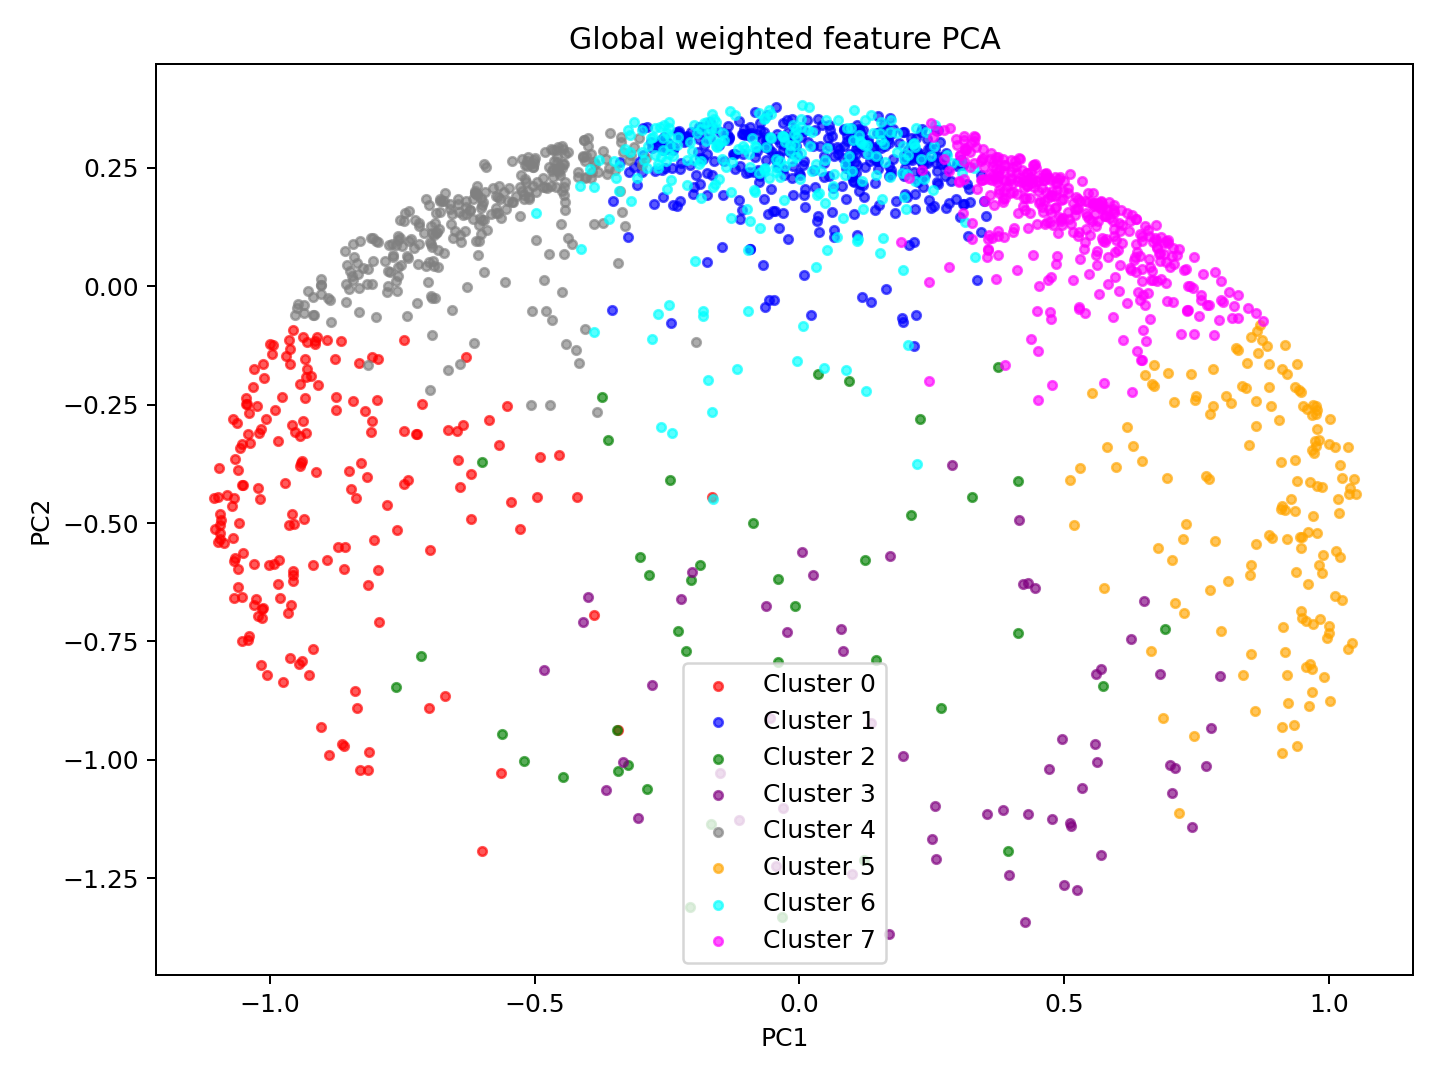

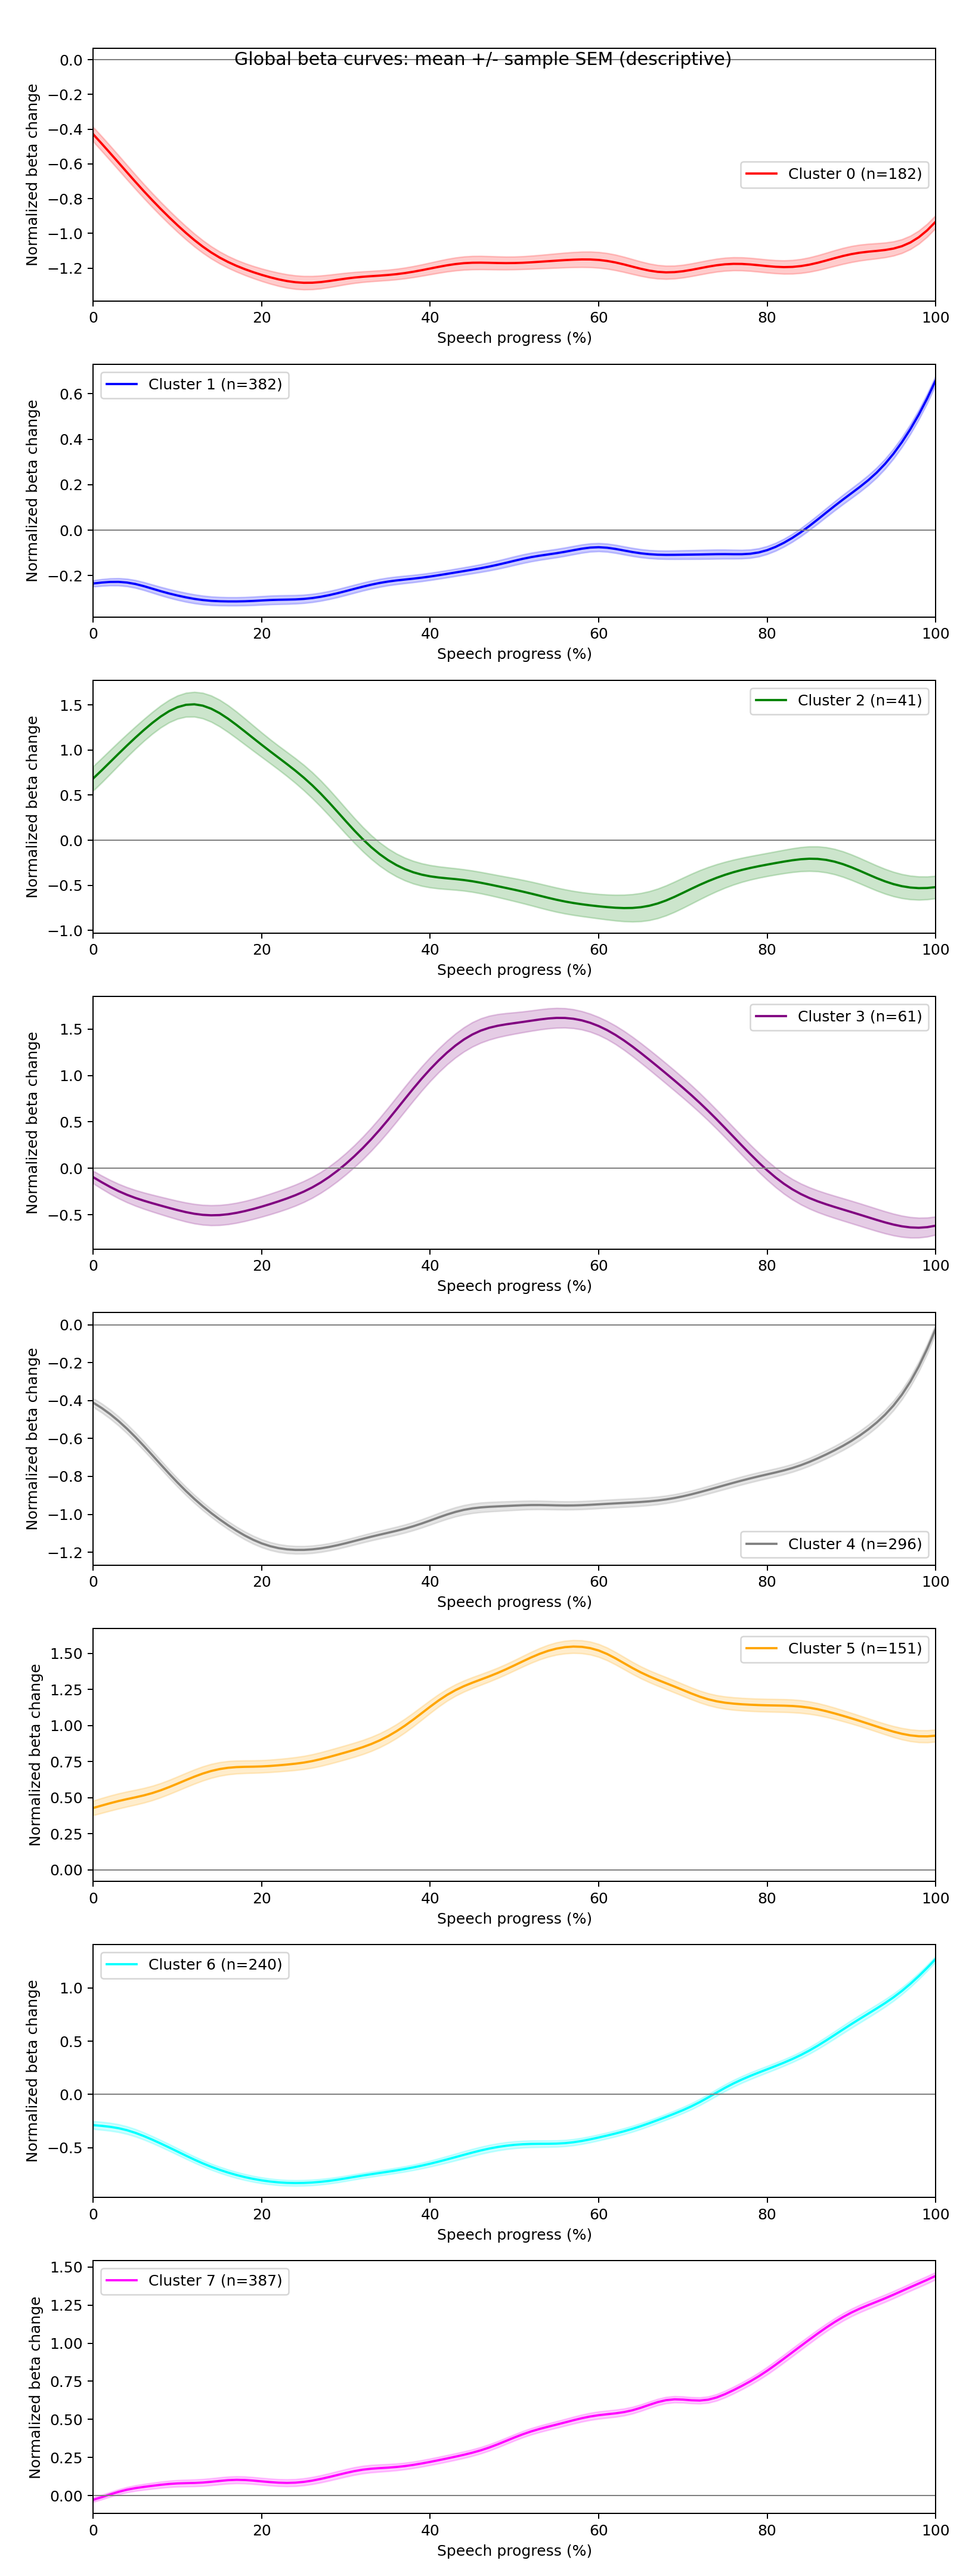

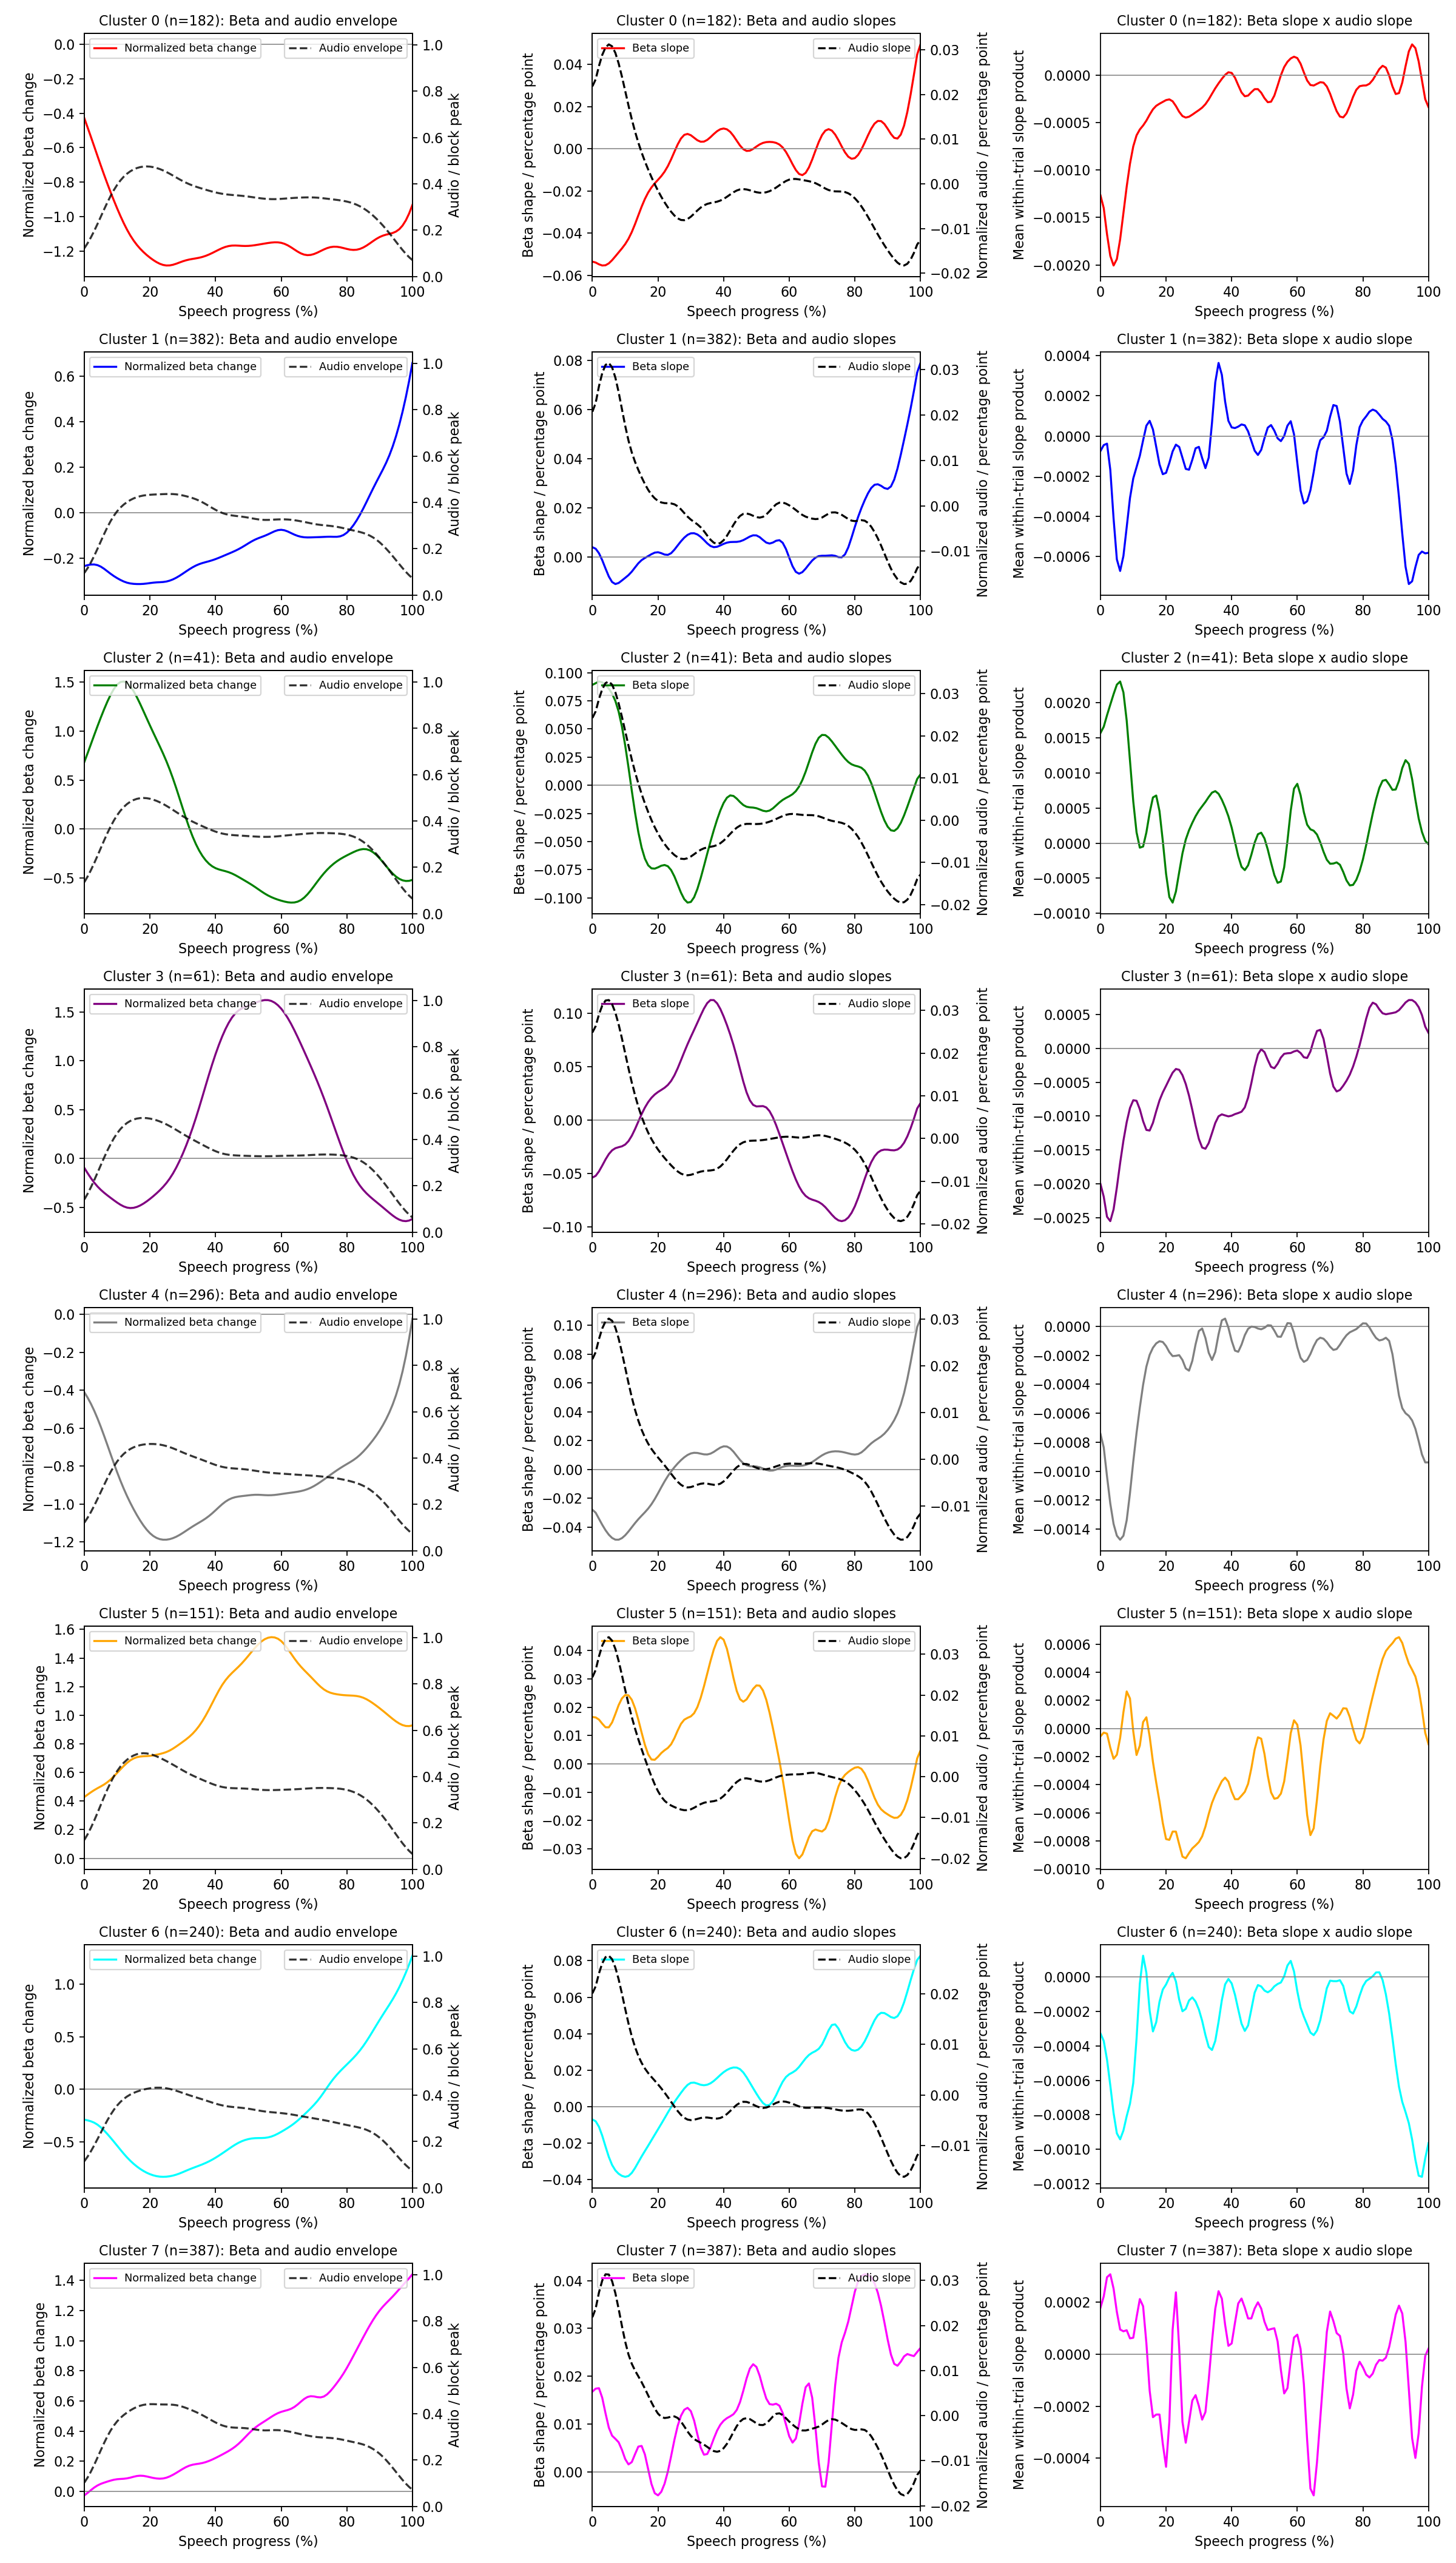

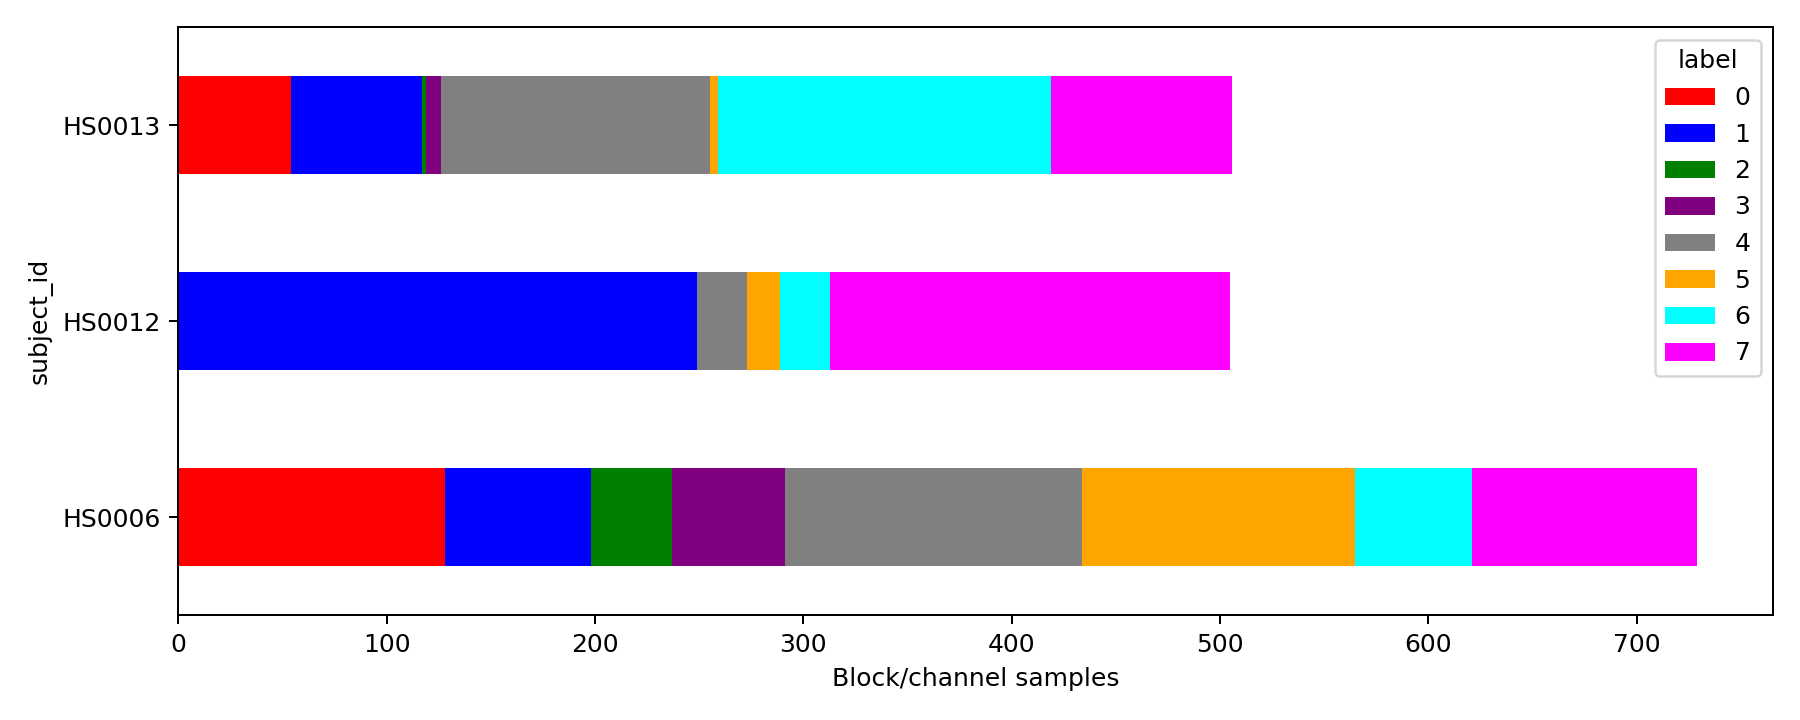

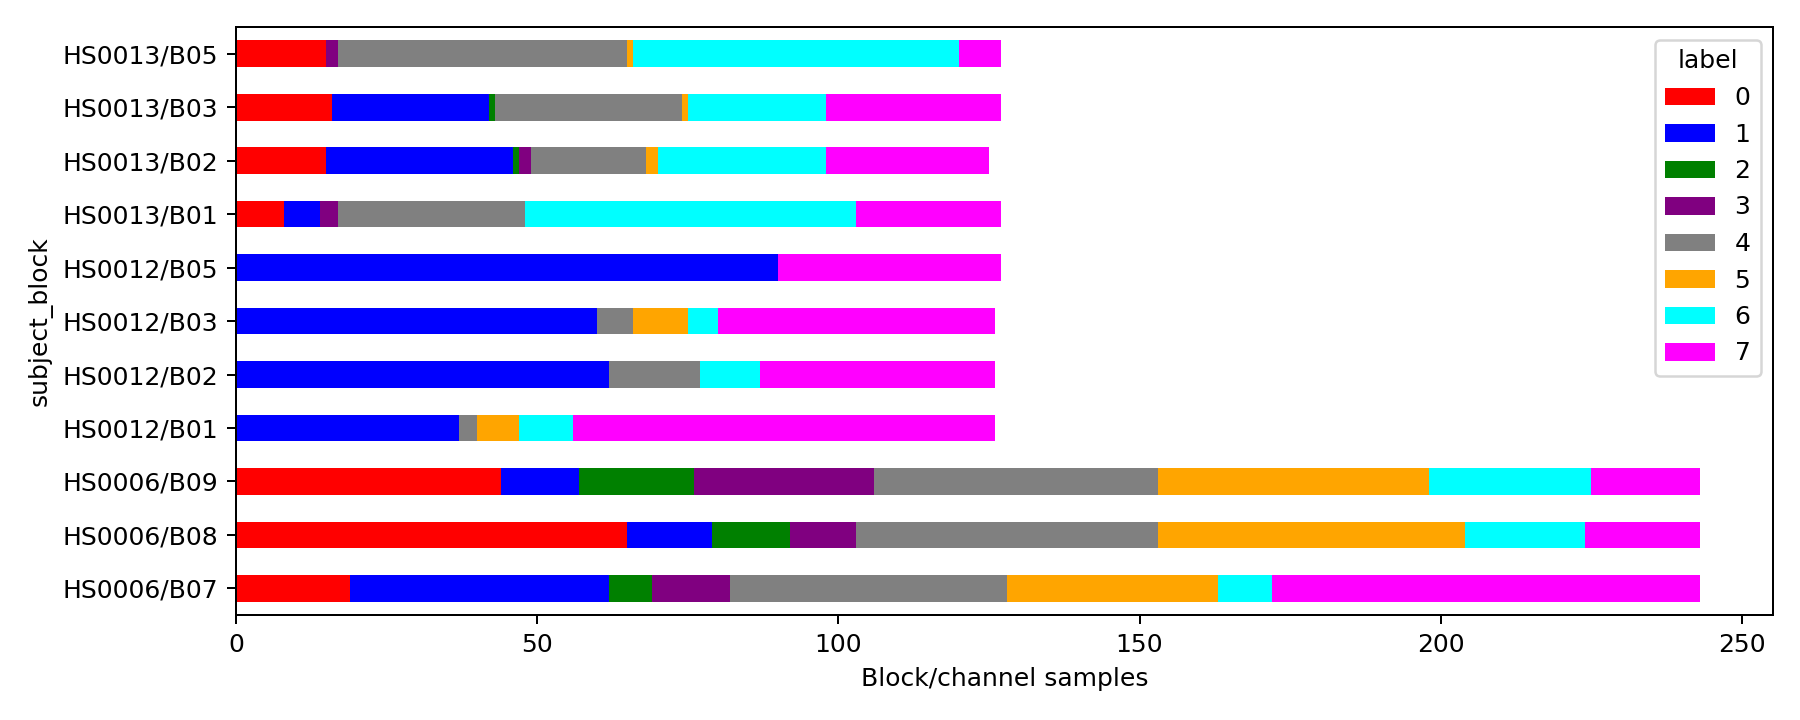

,sample_id,subject_id,block_id,channel,is_bad,exclusion_reason,first_label,first_pc1,first_pc2,first_pc3,pca_cluster_distance
1544,HS0013:B02:ECoG_9,HS0013,B02,ECoG_9,False,,3,-0.278772,-0.842881,0.708249,0.909307
542,HS0006:B07:ECoG_31,HS0006,B07,ECoG_31,False,,2,0.690734,-0.724656,0.628448,0.848318
1302,HS0013:B01:ECoG_23,HS0013,B01,ECoG_23,False,,0,-0.598769,-1.192663,0.230796,0.847217
822,HS0006:B08:ECoG_55,HS0006,B08,ECoG_55,False,,0,-0.342404,-0.935987,-0.477693,0.847075
895,HS0006:B08:ECoG_128,HS0006,B08,ECoG_128,False,,3,-0.063708,-0.674930,-0.701931,0.806920
1288,HS0013:B01:ECoG_9,HS0013,B01,ECoG_9,False,,3,-0.408802,-0.709698,0.349705,0.799455
890,HS0006:B08:ECoG_123,HS0006,B08,ECoG_123,False,,3,-0.055200,-0.912164,-0.719333,0.775594
1043,HS0006:B09:ECoG_20,HS0006,B09,ECoG_20,False,,3,-0.398477,-0.656824,-0.282911,0.769758
1672,HS0013:B05:ECoG_9,HS0013,B05,ECoG_9,False,,3,-0.482778,-0.809406,-0.028766,0.759641
949,HS0006:B08:ECoG_182,HS0006,B08,ECoG_182,False,,5,0.715727,-1.112230,0.353717,0.757729


In [39]:
import json
refresh_saved_plots(RUN_DIR)  # 从缓存刷新图形配色，不重读数据或重新分类。
display(json.loads((RUN_DIR / "global_summary.json").read_text(encoding="utf-8")))
for name in ["cluster_grid_beta_audio.png", "pca_clusters.png", "global_beta_curves.png", "beta_audio_dynamics.png", "cluster_subject_counts.png", "cluster_block_counts.png"]:
    display(Image(filename=str(RUN_DIR / name)))
first_review_table = pca_review_table(first_analysis.features, first_analysis.clustering)
display(first_review_table.sort_values("pca_cluster_distance", ascending=False).head(50))

## 6. 自动筛除一次，再弹窗人工剔除

默认开启自动筛除和 Tk 弹窗。自动条件必须同时成立：簇成员占第一轮合格样本比例 ≤5%，且前三个 PC 簇内样本方差之和 > 非小簇方差中位数的 3 倍。两个阈值可修改。只有一个成员的簇无法估计方差；没有非小簇参照时不自动剔除。报告先保存，再打开窗口。

窗口保留第一轮簇编号及坐标，支持旋转三维 PCA、勾选坏簇、输入 sample_id、设置第二轮 K。自动剔除点显示为白色 Bad，不再提供对应簇勾选。关闭未 Apply 时停止，第二轮不会执行。

In [40]:
BAD_CLUSTERS = ()  # 第一轮异常簇编号，例如 (3,)
MANUAL_BAD_SAMPLES = ()  # 例如 ("HS0012:B01:ECoG_124",)
PCA_DISTANCE_THRESHOLD = None  # 可选：前三 PC 到所属簇中心的绝对距离
OPEN_REVIEW_WINDOW = True  # 默认弹窗人工剔除
AUTO_PRUNE_ENABLED = True
AUTO_SMALL_CLUSTER_FRACTION = 0.05
AUTO_PCA_VARIANCE_RATIO = 3.0

# 一次自动筛除：不改变第一轮模型，不增加中间聚类。
review_ready = False
automatic_pruning = screen_small_high_variance_clusters(
    first_analysis.features, first_analysis.clustering,
    enabled=AUTO_PRUNE_ENABLED, small_fraction=AUTO_SMALL_CLUSTER_FRACTION,
    variance_ratio=AUTO_PCA_VARIANCE_RATIO,
)
AUTO_REVIEW_DIR = RUN_DIR / ("review_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
AUTO_REVIEW_DIR.mkdir()
automatic_pruning.cluster_report.to_csv(AUTO_REVIEW_DIR / "auto_cluster_screening.csv", index=False, encoding="utf-8-sig")
automatic_pruning.sample_report.to_csv(AUTO_REVIEW_DIR / "auto_sample_screening.csv", index=False, encoding="utf-8-sig")
(AUTO_REVIEW_DIR / "auto_policy.json").write_text(json.dumps(automatic_pruning.policy, ensure_ascii=False, indent=2), encoding="utf-8")
display(automatic_pruning.cluster_report)
print("自动剔除簇：", automatic_pruning.bad_clusters)
print("自动剔除样本数：", int(automatic_pruning.bad_mask.sum()))

selected_bad_clusters = tuple(BAD_CLUSTERS)
selected_manual_samples = tuple(MANUAL_BAD_SAMPLES)
selected_second_k = int(SECOND_N_CLUSTERS)
if OPEN_REVIEW_WINDOW:
    review = show_pruned_review_window(first_analysis.clustering, automatic_pruning, initial_second_k=selected_second_k)
    if review is None:
        raise RuntimeError("复审窗口关闭，未点击 Apply；第二轮未执行。请重新运行本单元进行复审。")
    selected_bad_clusters = tuple(sorted(set(selected_bad_clusters) | set(review.bad_clusters)))
    selected_manual_samples = tuple(sorted(set(selected_manual_samples) | set(review.manual_bads)))
    selected_second_k = review.n_clusters
reviewed_first_round_dir = first_analysis.output_dir
review_ready = True
print("排除第一轮簇：", selected_bad_clusters)
print("手动排除样本：", selected_manual_samples)
print("PCA 距离阈值：", PCA_DISTANCE_THRESHOLD)
print("第二轮类数：", selected_second_k)

,label,n_samples,size_fraction,pca_variance,variance_estimable,is_small,reference_variance,variance_threshold,is_high_variance,auto_excluded,auto_reason
0,0,182,0.104598,0.117972,True,False,0.077843,0.233528,False,False,not_small
1,1,382,0.219540,0.055248,True,False,0.077843,0.233528,False,False,not_small
2,2,41,0.023563,0.316172,True,True,0.077843,0.233528,True,True,small_and_high_variance
3,3,61,0.035057,0.291031,True,True,0.077843,0.233528,True,True,small_and_high_variance
4,4,296,0.170115,0.064685,True,False,0.077843,0.233528,False,False,not_small
5,5,151,0.086782,0.114657,True,False,0.077843,0.233528,False,False,not_small
6,6,240,0.137931,0.077256,True,False,0.077843,0.233528,False,False,not_small
7,7,387,0.222414,0.078430,True,False,0.077843,0.233528,False,False,not_small


自动剔除簇： (2, 3)
自动剔除样本数： 102
排除第一轮簇： ()
手动排除样本： ()
PCA 距离阈值： None
第二轮类数： 4


## 7. 执行第二轮分类

自动排除、弹窗人工排除及原始质量排除合并，全部保留 -1 标签与各自原因。重新筛选曲线/关系特征，独立拟合缺失值填充、全局共享 beta 尺度、K-means 与 PCA，同样去除通道响应幅度差异，只比较形状及音频关系。第一轮文件保持不变；每次第二轮使用独立子目录。修改自动阈值或人工选择只需重跑第 6–8 节。

In [41]:
if not globals().get("review_ready", False) or reviewed_first_round_dir != first_analysis.output_dir:
    raise RuntimeError("请先完成当前第一轮的第 6 节自动筛除及人工复审。")
SECOND_RUN_DIR = RUN_DIR / ("round2_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
second_analysis = run_second_round(
    first_analysis, SECOND_RUN_DIR, second_n_clusters=selected_second_k,
    bad_clusters=selected_bad_clusters, manual_bad_samples=selected_manual_samples,
    pca_distance_threshold=PCA_DISTANCE_THRESHOLD,
    random_state=RANDOM_STATE, correlation_threshold=CORRELATION_THRESHOLD,
    automatic_pruning=automatic_pruning,
)
print("第二轮输出目录：", second_analysis.output_dir)
display(second_analysis.assignments.groupby("label").size().rename("n_samples"))
display(pd.read_csv(SECOND_RUN_DIR / "review_audit.csv"))

第二轮输出目录： I:\贝塔频带汇报-2026-10\all-channel\outputs\20261004_224012_479439\round2_20261004_232124_674092


label
-1    154
 0    294
 1    548
 2    191
 3    605
Name: n_samples, dtype: int64

,sample_id,subject_id,block_id,channel,is_bad,exclusion_reason,first_label,first_pc1,first_pc2,first_pc3,pca_cluster_distance,excluded_cluster,excluded_auto_cluster,excluded_manual,excluded_distance,excluded_final,second_label
0,HS0012:B01:ECoG_1,HS0012,B01,ECoG_1,False,NaN,7,0.637641,-0.136146,0.166847,0.362143,False,False,False,False,False,2
1,HS0012:B01:ECoG_2,HS0012,B01,ECoG_2,False,NaN,5,0.695043,-0.184134,0.080039,0.345301,False,False,False,False,False,2
2,HS0012:B01:ECoG_3,HS0012,B01,ECoG_3,False,NaN,7,0.449212,-0.052692,0.083605,0.230810,False,False,False,False,False,3
3,HS0012:B01:ECoG_4,HS0012,B01,ECoG_4,False,NaN,1,0.309656,0.174442,0.322951,0.318294,False,False,False,False,False,3
4,HS0012:B01:ECoG_5,HS0012,B01,ECoG_5,False,NaN,7,0.375924,0.204249,0.234045,0.316906,False,False,False,False,False,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1787,HS0013:B05:ECoG_124,HS0013,B05,ECoG_124,False,NaN,6,-0.388192,0.209228,-0.390002,0.361391,False,False,False,False,False,1
1788,HS0013:B05:ECoG_125,HS0013,B05,ECoG_125,False,NaN,6,-0.496665,0.155494,-0.381043,0.467053,False,False,False,False,False,1
1789,HS0013:B05:ECoG_126,HS0013,B05,ECoG_126,False,NaN,6,-0.340483,0.200251,-0.340338,0.301136,False,False,False,False,False,1
1790,HS0013:B05:ECoG_127,HS0013,B05,ECoG_127,False,NaN,6,-0.035978,0.231263,-0.329790,0.073305,False,False,False,False,False,1


## 8. 查看第二轮结果

主图与示例一致：彩色 beta 均值与样本 SEM、橙色音频包络双轴、onset/offset 虚线和固定 pre/post。图与模型均使用完整连续曲线去 pre 均值并按逐通道 RMS 归一化的无量纲变化，不再保留 beta Z 显示。语音段映射到所有纳入 trial 时长的中位数，仅用于图上毫秒轴；pre/post 保留真实秒数。各簇编号在重拟合后可能改变，不应按编号对应第一轮。第一轮还保存每个通道的图及 trial SEM，见 channel_figure_index.csv。样本 SEM 仅描述分散程度；人工复审、轮廓系数和 PCA 不证明稳定性或生理类别。

{'n_samples': 1792,
 'n_included': 1638,
 'n_requested_clusters': 4,
 'n_actual_clusters': 4,
 'min_cluster_size': 191,
 'silhouette': 0.22919572857881548,
 'silhouette_sample_cap': 5000,
 'stability_evaluated': False,
 'interpretation': 'Descriptive clustering and paired beta/audio curves; sample SEM is not a stability test.',
 'classification_mode': 'curve_shape',
 'distance': 'weighted Euclidean',
 'beta_centering': 'subtract each sample pre-onset mean; divide full curve by its own RMS',
 'shared_beta_scale': 1.0}

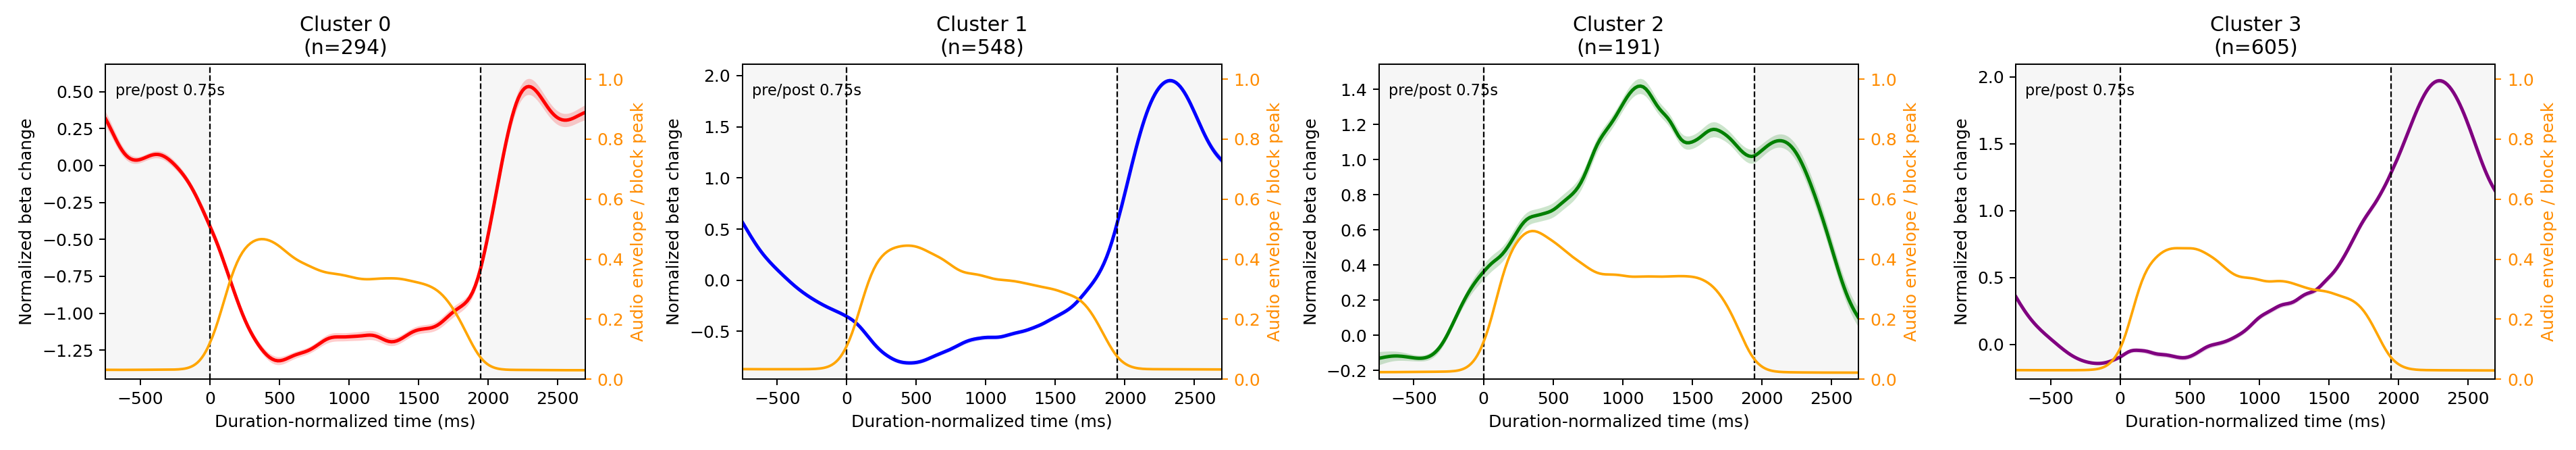

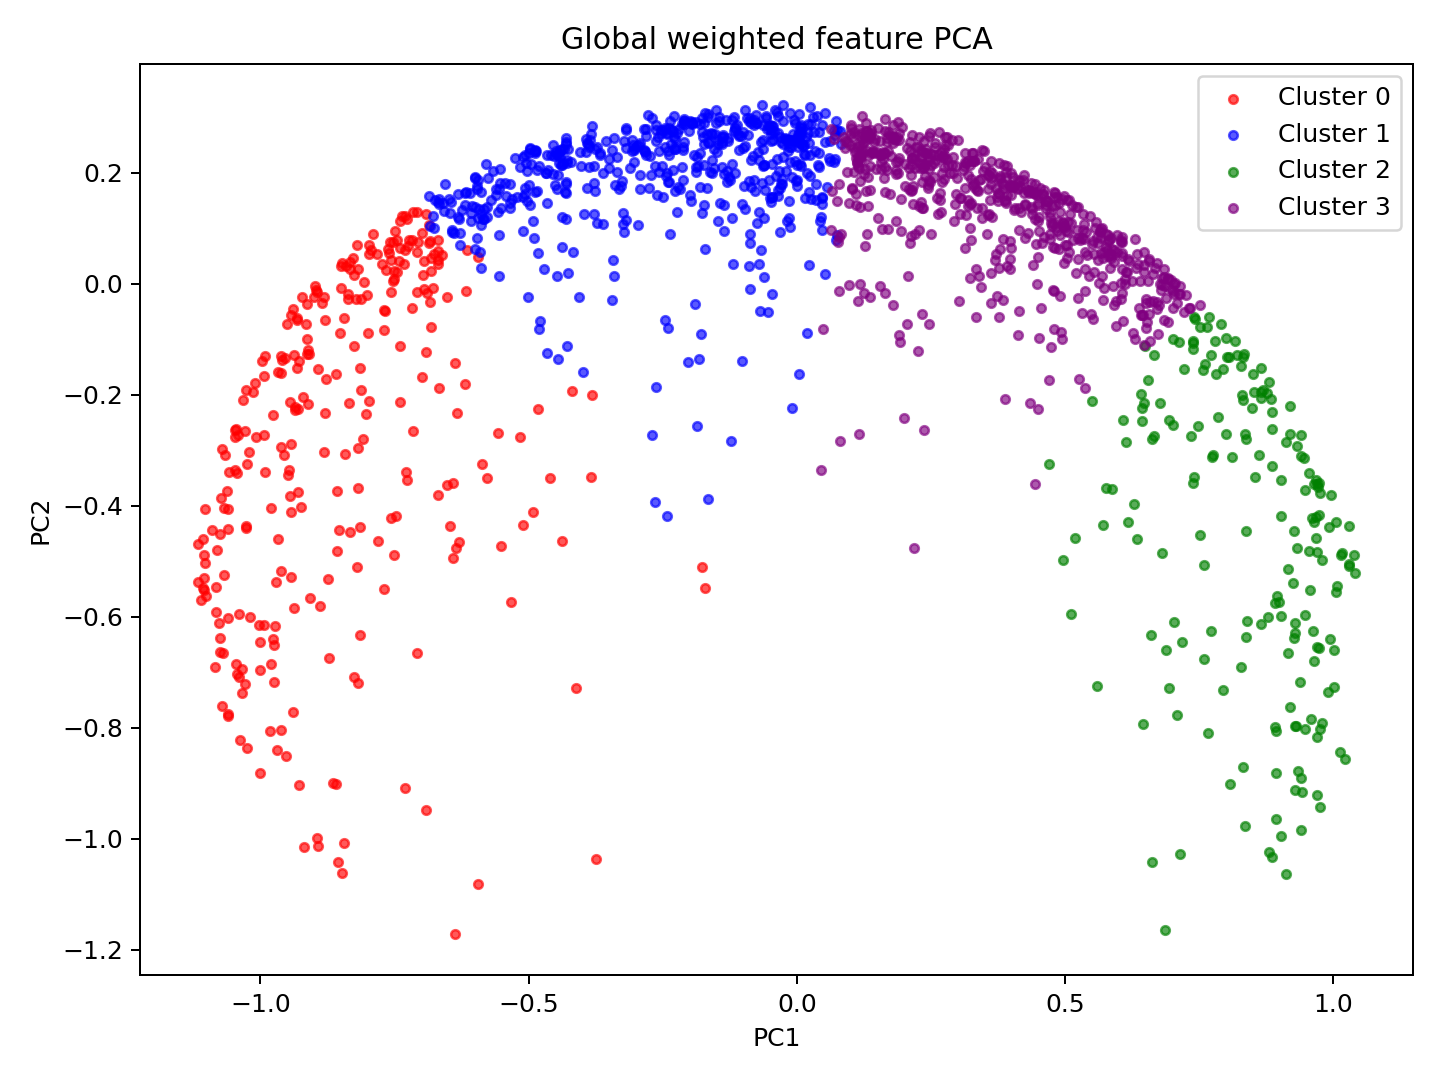

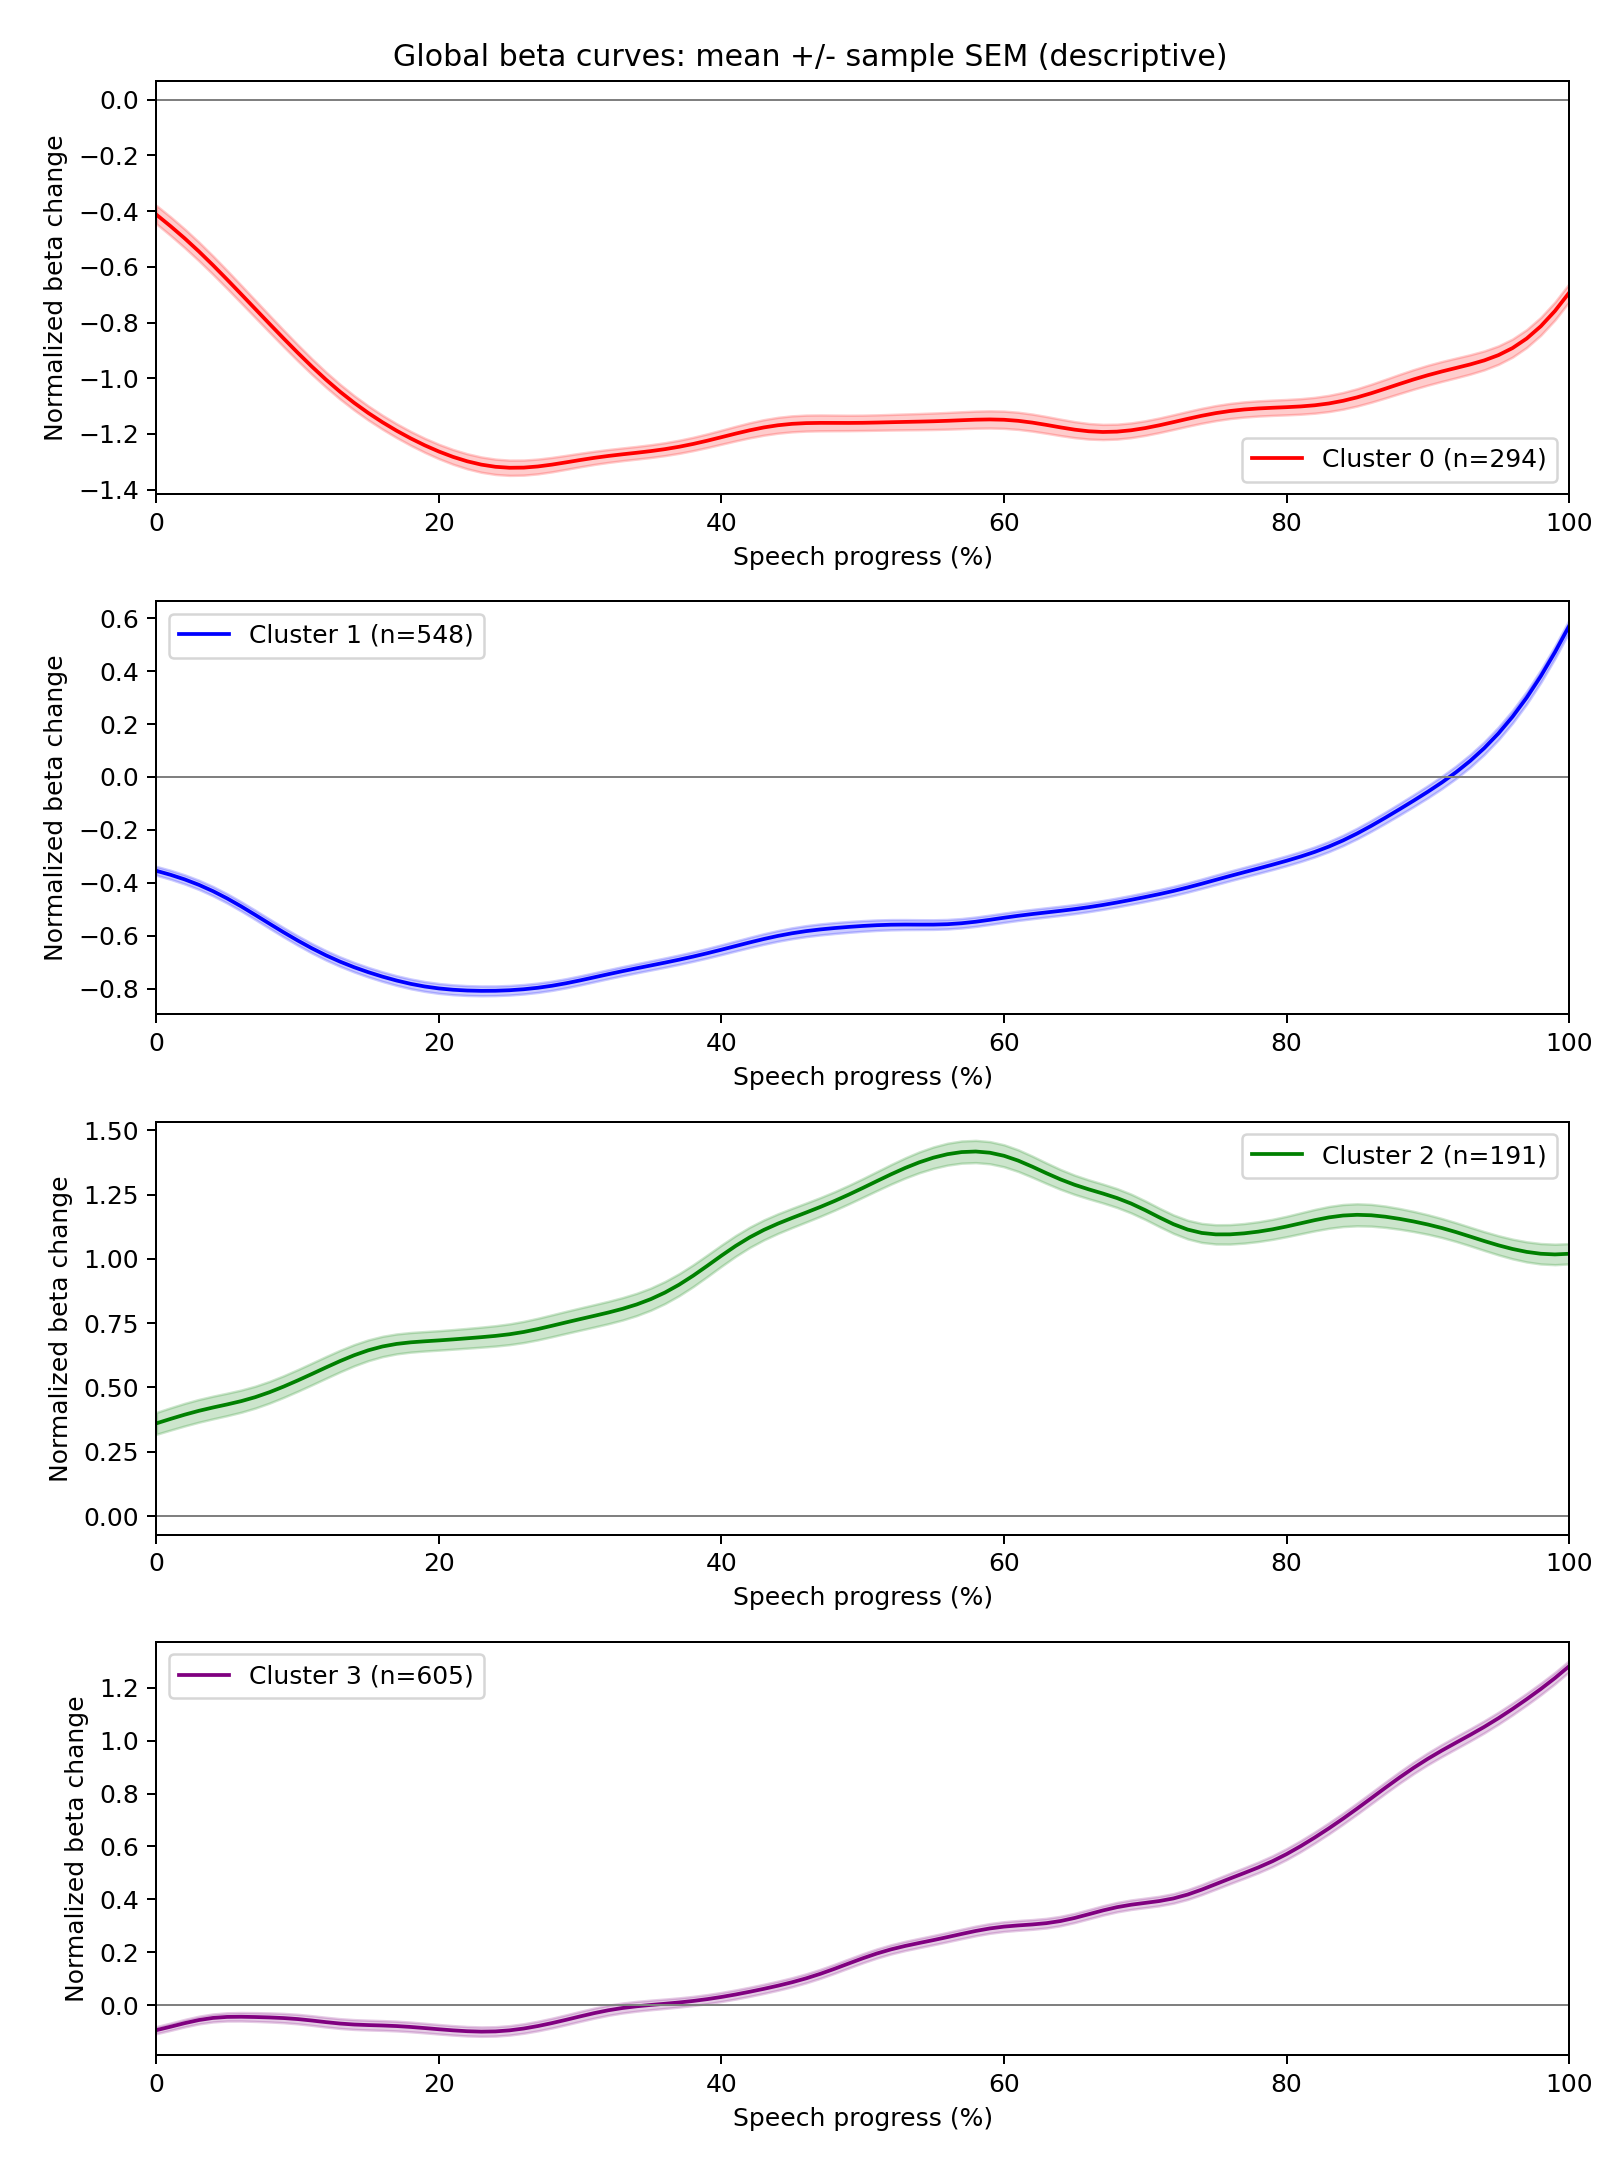

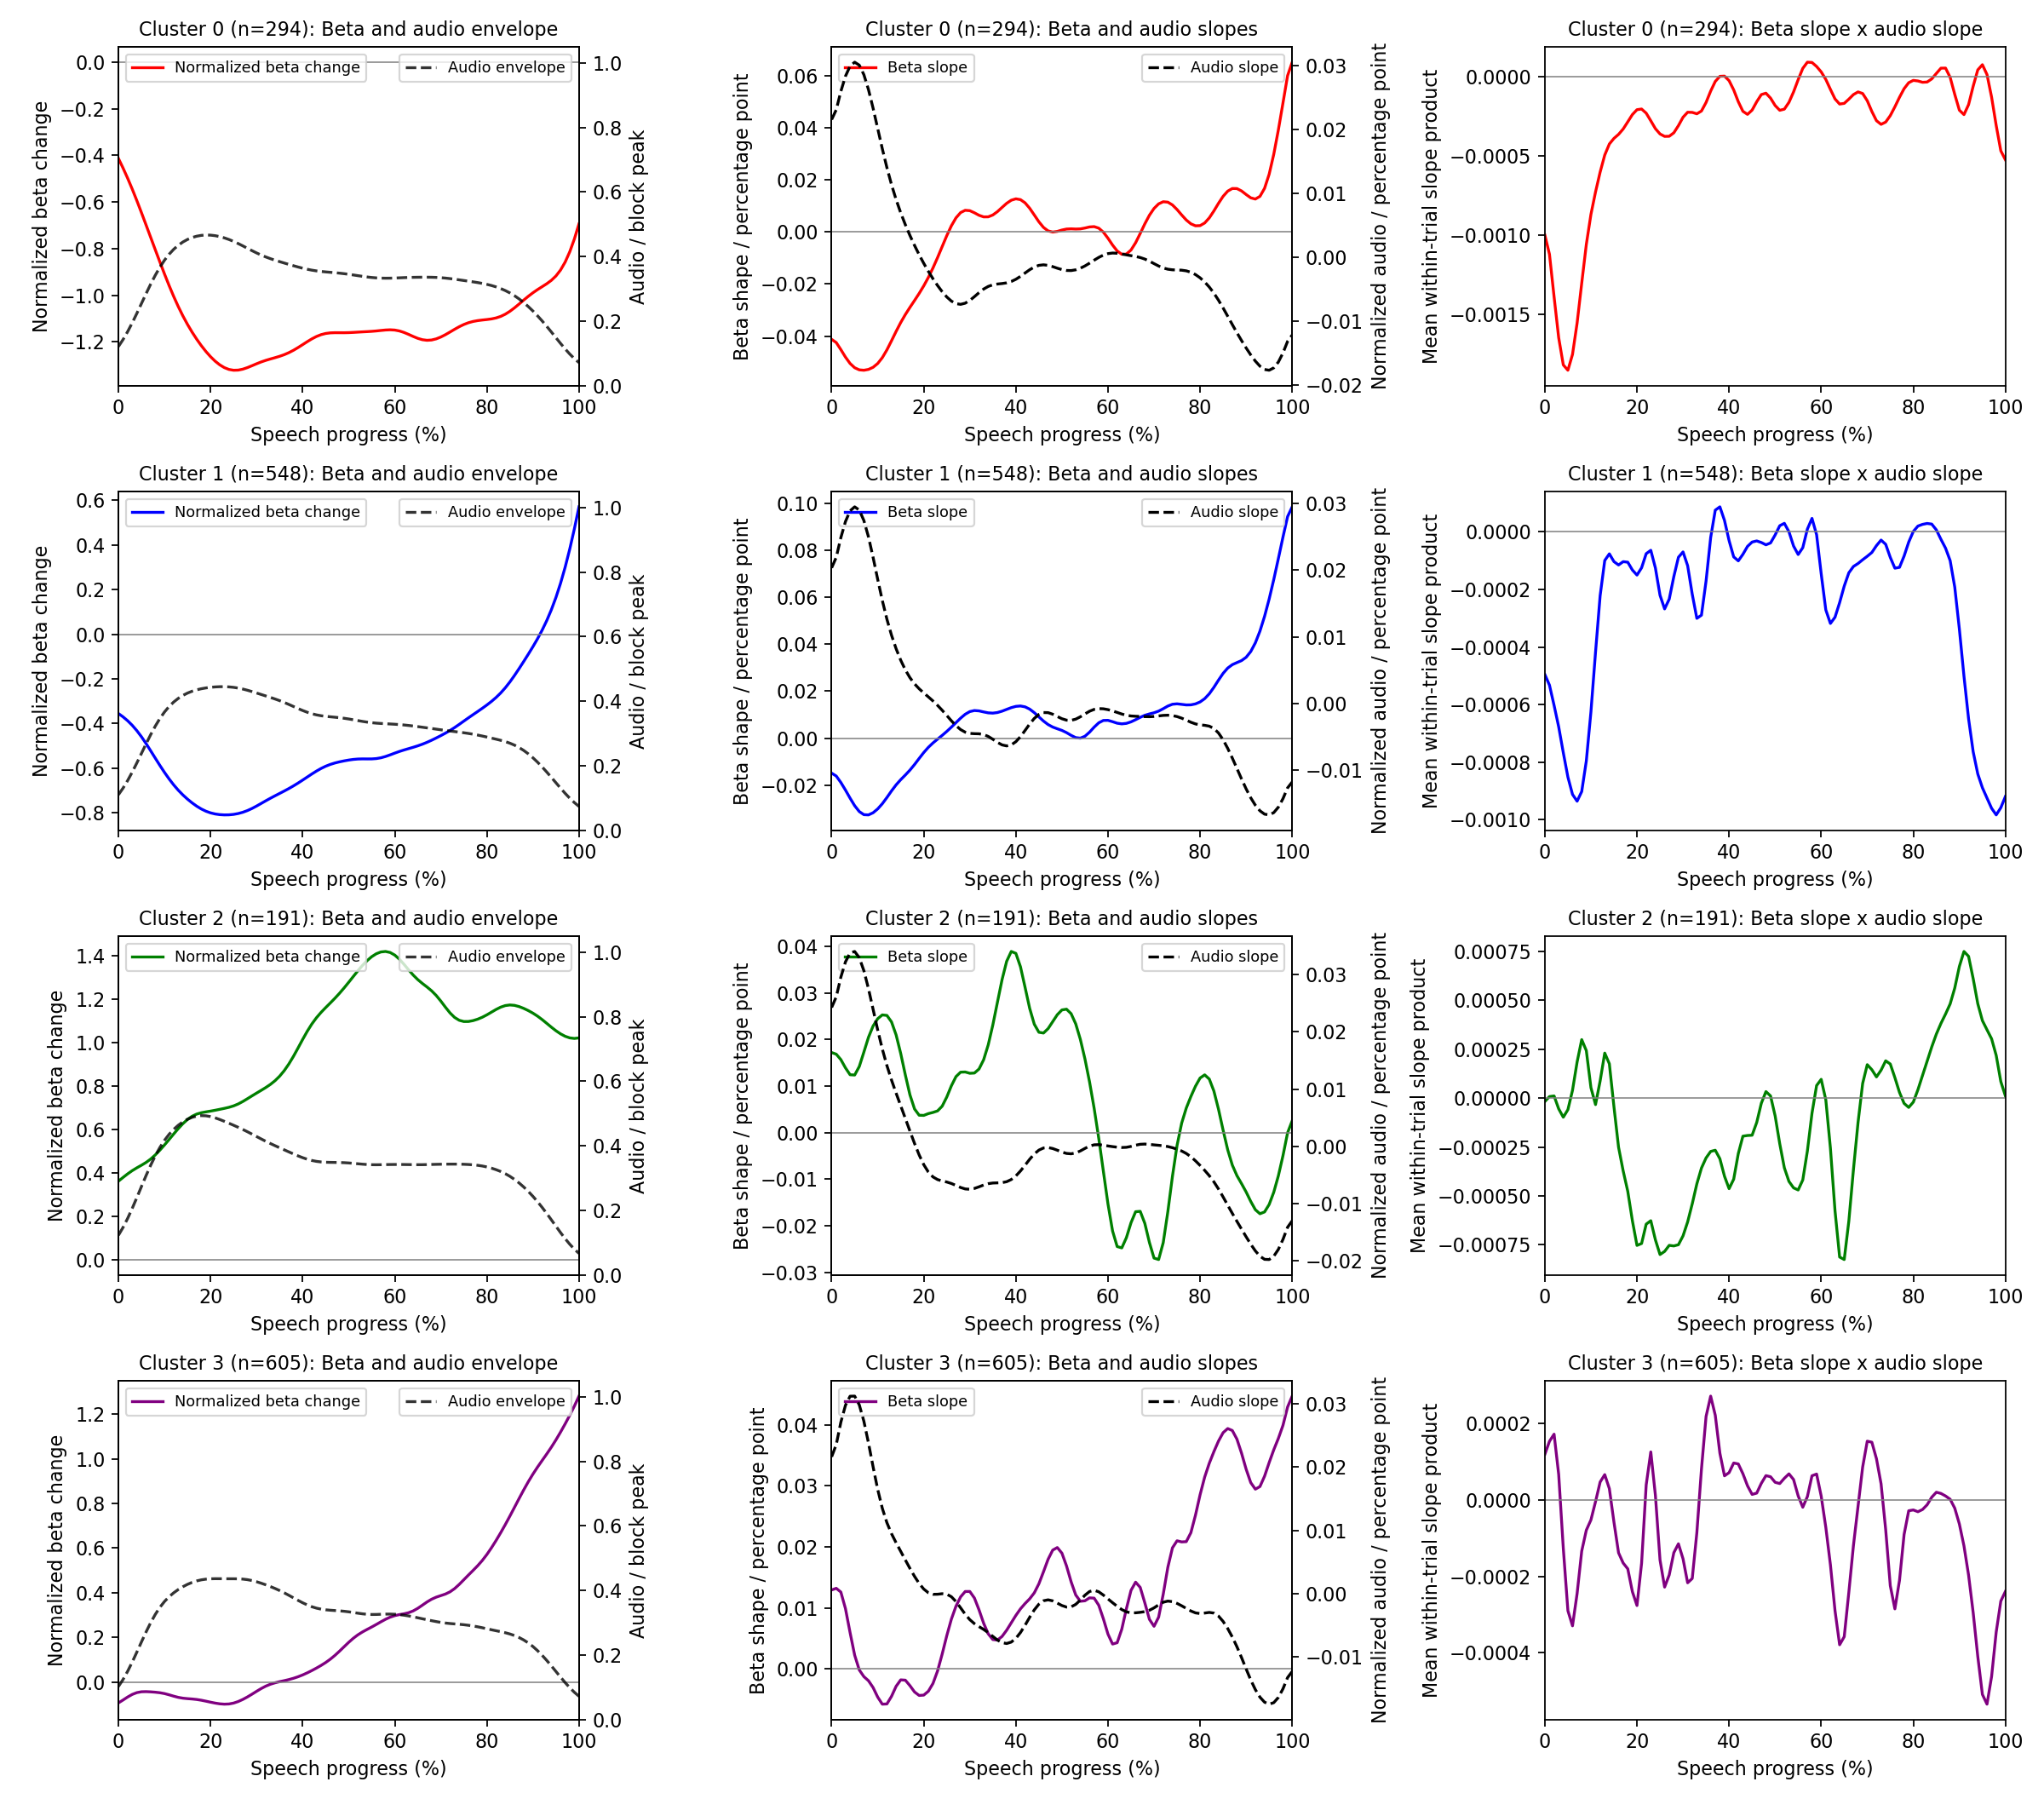

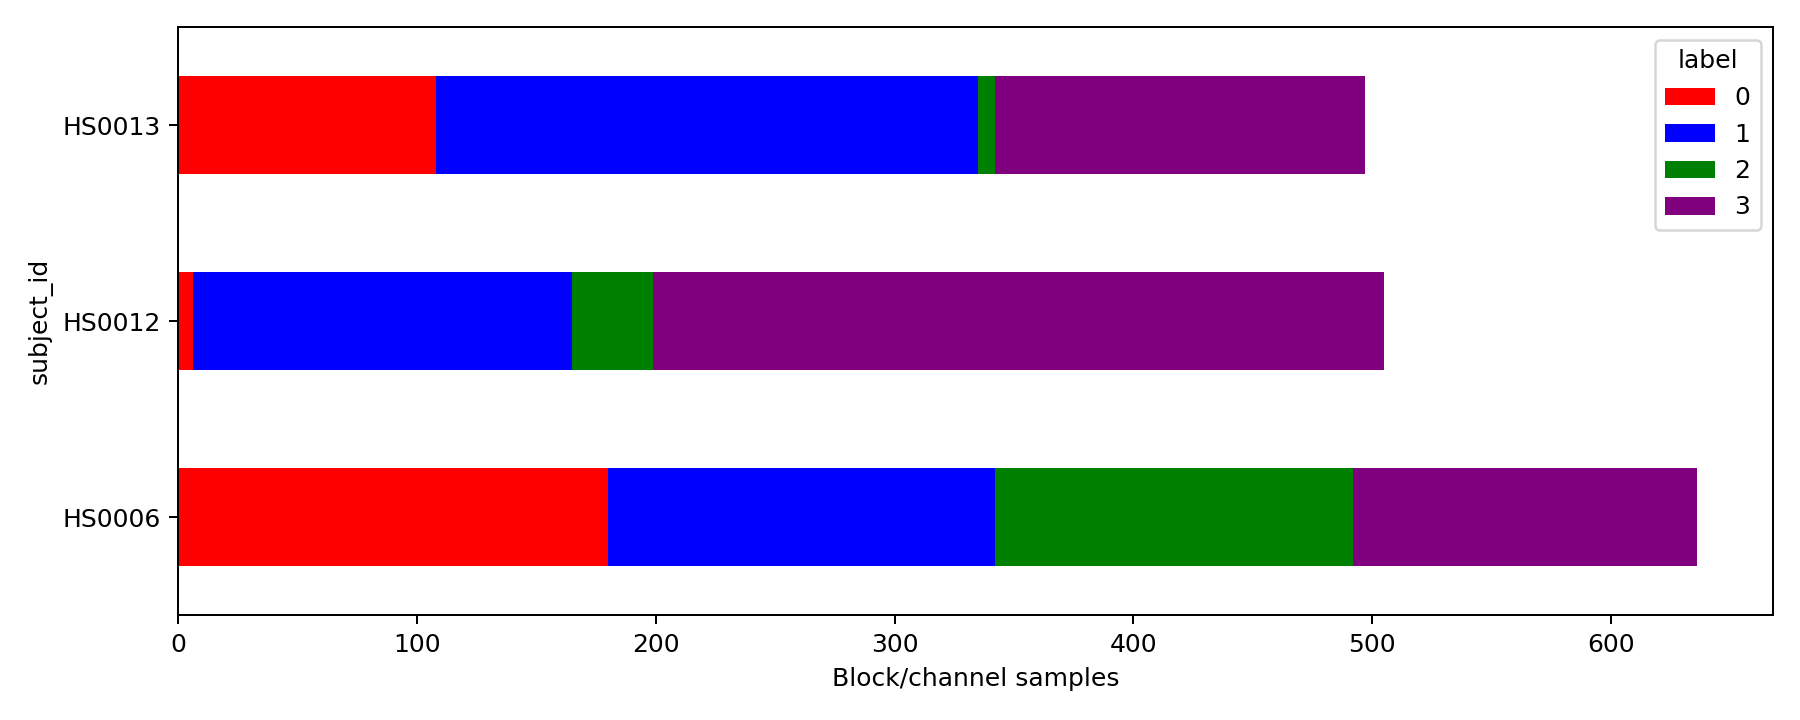

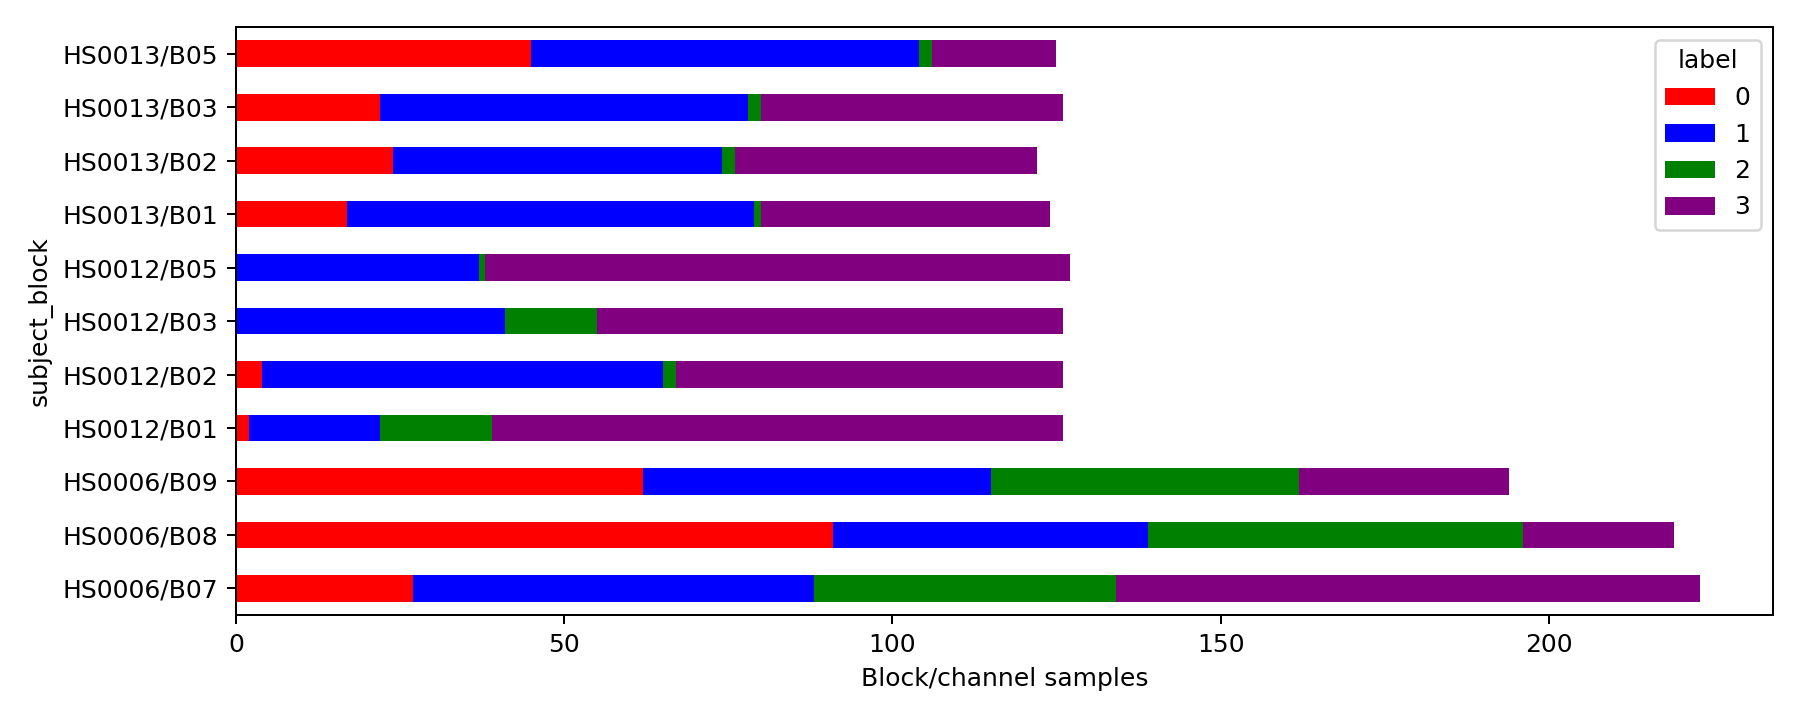

In [42]:
refresh_saved_plots(SECOND_RUN_DIR)  # 从缓存刷新图形配色，不重新分类。
display(json.loads((SECOND_RUN_DIR / "global_summary.json").read_text(encoding="utf-8")))
for name in ["cluster_grid_beta_audio.png", "pca_clusters.png", "global_beta_curves.png", "beta_audio_dynamics.png", "cluster_subject_counts.png", "cluster_block_counts.png"]:
    display(Image(filename=str(SECOND_RUN_DIR / name)))